# 1. Problem (Identifikasi Masalah)


Judul proyek:

Klasifikasi Kebutuhan Pendampingan Belajar Mahasiswa Berdasarkan Aktivitas Akademik

Masalah: Kesulitan mengidentifikasi mahasiswa yang membutuhkan pendampingan belajar berdasarkan aktivitas dan performa akademik.

Tujuan: Membangun model Machine Learning untuk mengklasifikasikan kebutuhan pendampingan belajar mahasiswa menjadi dua kategori:

Ya: Memerlukan pendampingan.

Tidak: Tidak memerlukan pendampingan berdasarkan indikator yang ditentukan.

Solusi: Menggunakan Decision Tree sebagai algoritma utama dan Random Forest sebagai algoritma pembanding.

# 2. Data Collection (Pengumpulan Data)


IMPORT LIBRARY

In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from google.colab import files
import io

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


In [67]:
# 1. Upload file CSV (akan muncul tombol "Choose Files")
uploaded = files.upload()

# 2. Baca dataset
nama_file = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[nama_file]))

print("Nama file:", nama_file)
print("Dataset berhasil dibaca!")
df.head()

Saving student_performance_clean.csv to student_performance_clean (1).csv
Nama file: student_performance_clean (1).csv
Dataset berhasil dibaca!


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
0,19,64,1,0,0,1,0,19,2,8,1,59,40,0,1,3
1,19,64,1,0,0,1,0,23,3,16,0,90,66,0,1,2
2,19,64,1,0,0,1,0,28,1,19,0,67,99,1,1,0
3,19,64,1,1,0,1,0,19,2,8,1,59,40,0,1,3
4,19,64,1,1,0,1,0,23,3,16,0,90,66,0,1,2


Membaca Dataset

In [68]:
nama_file = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[nama_file]))

print("Nama file:", nama_file)
print("Dataset berhasil dibaca!")

Nama file: student_performance_clean (1).csv
Dataset berhasil dibaca!


# 3. Data Understanding (Pemahaman Data)

Menampilkan 5 data teratas

In [69]:
df.head()

,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
0,19,64,1,0,0,1,0,19,2,8,1,59,40,0,1,3
1,19,64,1,0,0,1,0,23,3,16,0,90,66,0,1,2
2,19,64,1,0,0,1,0,28,1,19,0,67,99,1,1,0
3,19,64,1,1,0,1,0,19,2,8,1,59,40,0,1,3
4,19,64,1,1,0,1,0,23,3,16,0,90,66,0,1,2


Melihat Jumlah Baris dan Kolom

In [70]:
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

Jumlah baris: 12467
Jumlah kolom: 16


In [71]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12467 entries, 0 to 12466
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   StudyHours            12467 non-null  int64
 1   Attendance            12467 non-null  int64
 2   Resources             12467 non-null  int64
 3   Extracurricular       12467 non-null  int64
 4   Motivation            12467 non-null  int64
 5   Internet              12467 non-null  int64
 6   Gender                12467 non-null  int64
 7   Age                   12467 non-null  int64
 8   LearningStyle         12467 non-null  int64
 9   OnlineCourses         12467 non-null  int64
 10  Discussions           12467 non-null  int64
 11  AssignmentCompletion  12467 non-null  int64
 12  ExamScore             12467 non-null  int64
 13  EduTech               12467 non-null  int64
 14  StressLevel           12467 non-null  int64
 15  FinalGrade            12467 non-null  int64
dtypes: i

In [72]:
df.describe()

,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
count,12467.000000,12467.000000,12467.000000,12467.000000,12467.000000,12467.000000,12467.000000,12467.000000,12467.000000,12467.000000,12467.000000,12467.000000,12467.000000,12467.000000,12467.000000,12467.000000
mean,20.030641,80.239753,1.101468,0.583139,0.907436,0.917061,0.538702,23.529077,1.515120,9.873265,0.606240,74.514879,70.310500,0.707307,1.305366,1.451432
std,6.042660,11.469308,0.711159,0.493059,0.709608,0.275801,0.498520,3.511026,1.116002,6.114054,0.488602,14.656284,17.697226,0.455017,0.785440,1.122075
min,5.000000,60.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.000000,0.000000,0.000000,0.000000,50.000000,40.000000,0.000000,0.000000,0.000000
25%,16.000000,70.000000,1.000000,0.000000,0.000000,1.000000,0.000000,20.000000,1.000000,5.000000,0.000000,62.000000,55.000000,0.000000,1.000000,0.000000
50%,20.000000,80.000000,1.000000,1.000000,1.000000,1.000000,1.000000,24.000000,2.000000,10.000000,1.000000,74.000000,70.000000,1.000000,2.000000,1.000000
75%,24.000000,90.000000,2.000000,1.000000,1.000000,1.000000,1.000000,27.000000,3.000000,15.000000,1.000000,87.000000,86.000000,1.000000,2.000000,2.000000
max,39.000000,100.000000,2.000000,1.000000,2.000000,1.000000,1.000000,29.000000,3.000000,20.000000,1.000000,100.000000,100.000000,1.000000,2.000000,3.000000


Memeriksa Nama Kolom

In [73]:
print("Daftar kolom dataset:")

for kolom in df.columns:
    print("-", kolom)

Daftar kolom dataset:
- StudyHours
- Attendance
- Resources
- Extracurricular
- Motivation
- Internet
- Gender
- Age
- LearningStyle
- OnlineCourses
- Discussions
- AssignmentCompletion
- ExamScore
- EduTech
- StressLevel
- FinalGrade


# 3. Preprocessing

Memeriksa Missing values

In [74]:
print("Jumlah data kosong setiap kolom:")

print(df.isnull().sum())

Jumlah data kosong setiap kolom:
StudyHours              0
Attendance              0
Resources               0
Extracurricular         0
Motivation              0
Internet                0
Gender                  0
Age                     0
LearningStyle           0
OnlineCourses           0
Discussions             0
AssignmentCompletion    0
ExamScore               0
EduTech                 0
StressLevel             0
FinalGrade              0
dtype: int64


Memeriksa data duplikat

In [75]:
print("Jumlah data duplikat:", df.duplicated().sum())

Jumlah data duplikat: 0


Menentukan Target Pendampingan

In [76]:
df["Perlu_Pendampingan"] = np.where(
    (df["Attendance"] < 70) |
    (df["AssignmentCompletion"] < 60) |
    (df["ExamScore"] < 60) |
    (df["StudyHours"] < 10),
    "Ya",
    "Tidak"
)

df[["Attendance", "AssignmentCompletion", "ExamScore",
    "StudyHours", "Perlu_Pendampingan"]].head()

,Attendance,AssignmentCompletion,ExamScore,StudyHours,Perlu_Pendampingan
0,64,59,40,19,Ya
1,64,90,66,19,Ya
2,64,67,99,19,Ya
3,64,59,40,19,Ya
4,64,90,66,19,Ya


Melihat Jumlah Masing-Masing Target

In [77]:
print(df["Perlu_Pendampingan"].value_counts())

Perlu_Pendampingan
Ya       7540
Tidak    4927
Name: count, dtype: int64


Menentukan Fitur

In [78]:
fitur = [
    "StudyHours",
    "Attendance",
    "AssignmentCompletion",
    "OnlineCourses",
    "Discussions",
    "ExamScore"
]

X = df[fitur]
y = df["Perlu_Pendampingan"]

print("Fitur yang digunakan:")
print(fitur)
print("\nTarget:", y.name)

Fitur yang digunakan:
['StudyHours', 'Attendance', 'AssignmentCompletion', 'OnlineCourses', 'Discussions', 'ExamScore']

Target: Perlu_Pendampingan


Mengubah Target Menjadi Numerik

In [79]:
y = y.map({
    "Tidak": 0,
    "Ya": 1
})

print(y.value_counts())

Perlu_Pendampingan
1    7540
0    4927
Name: count, dtype: int64


Membagi Data 80% dan 20%

In [80]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing :", len(X_test))

Jumlah data training: 9973
Jumlah data testing : 2494


#4. Training

Training Decision Tree

In [81]:
model_dt = DecisionTreeClassifier(
    random_state=42
)

model_dt.fit(X_train, y_train)

print("Model Decision Tree berhasil dilatih!")

Model Decision Tree berhasil dilatih!


Training Random Forest

In [82]:
model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model_rf.fit(X_train, y_train)

print("Model Random Forest berhasil dilatih!")

Model Random Forest berhasil dilatih!


#5. Evaluation

Prediksi Data Testing

In [83]:
y_pred_dt = model_dt.predict(X_test)
y_pred_rf = model_rf.predict(X_test)

print("Prediksi Decision Tree dan Random Forest berhasil!")

Prediksi Decision Tree dan Random Forest berhasil!


Evaluasi Decision Tree

In [84]:

print("Evaluasi Decision Tree")
print("Accuracy :", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_dt, zero_division=0))
print("F1-Score :", f1_score(y_test, y_pred_dt, zero_division=0))

Evaluasi Decision Tree
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-Score : 1.0


Evaluasi Random Forest

In [85]:
print("Evaluasi Random Forest")
print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_rf, zero_division=0))
print("F1-Score :", f1_score(y_test, y_pred_rf, zero_division=0))

Evaluasi Random Forest
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-Score : 1.0


Perbandingan Kedua Algoritma

In [86]:

hasil = pd.DataFrame({
    "Algoritma": ["Decision Tree", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_dt, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_dt, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_dt, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ]
})

hasil

,Algoritma,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,1.0,1.0,1.0,1.0
1,Random Forest,1.0,1.0,1.0,1.0


Visualisasi Perbandingan

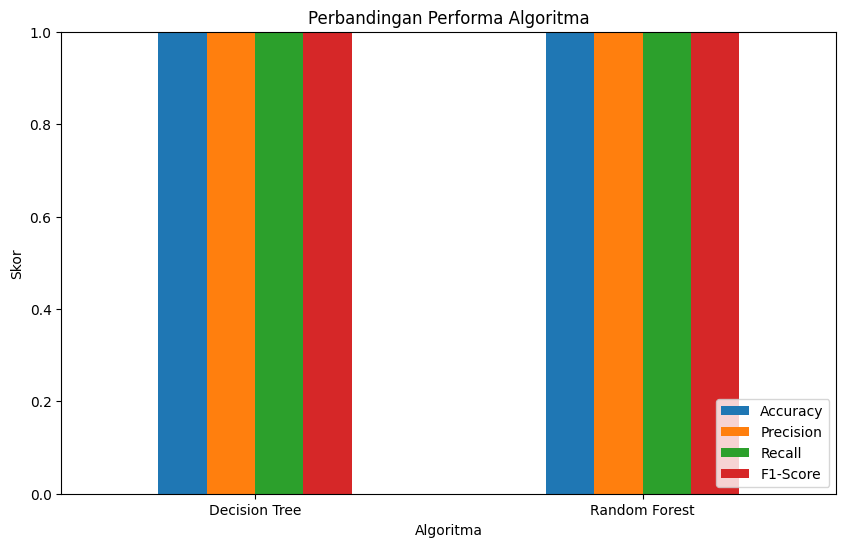

In [87]:
hasil_plot = hasil.set_index("Algoritma")

hasil_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Perbandingan Performa Algoritma")
plt.ylabel("Skor")
plt.xlabel("Algoritma")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

Confusion Matrix

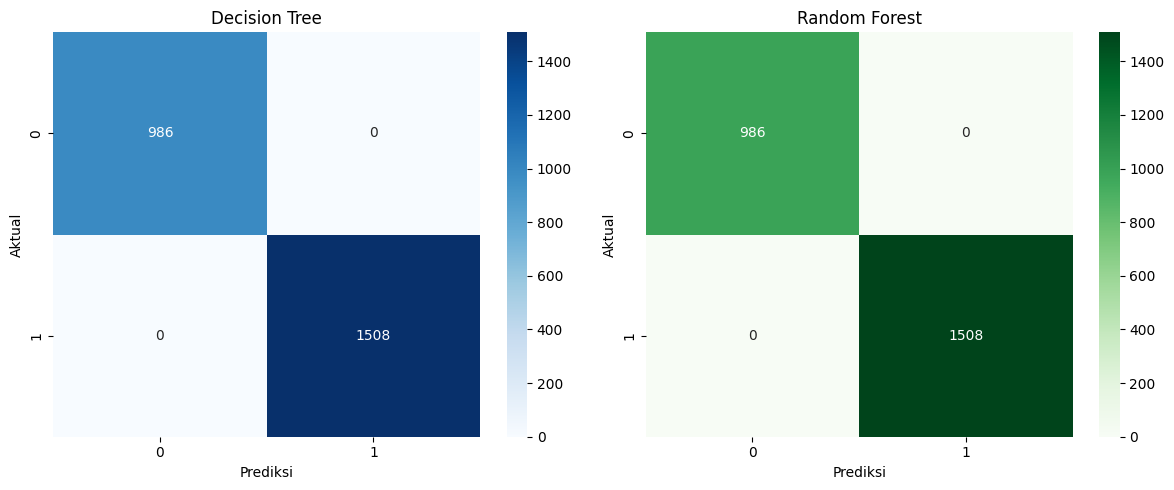

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_dt = confusion_matrix(y_test, y_pred_dt)
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Decision Tree")
axes[0].set_xlabel("Prediksi")
axes[0].set_ylabel("Aktual")

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Prediksi")
axes[1].set_ylabel("Aktual")

plt.tight_layout()
plt.show()

#6. Deployment

Membuat Data Mahasiswa Baru

In [89]:
data_baru = pd.DataFrame({
    "StudyHours": [15],
    "Attendance": [65],
    "AssignmentCompletion": [55],
    "OnlineCourses": [3],
    "Discussions": [2],
    "ExamScore": [58]
})

data_baru

,StudyHours,Attendance,AssignmentCompletion,OnlineCourses,Discussions,ExamScore
0,15,65,55,3,2,58


Melakukan Prediksi

In [90]:
prediksi = model_dt.predict(data_baru)

hasil_prediksi = "Ya" if prediksi[0] == 1 else "Tidak"

print("Hasil Prediksi:", hasil_prediksi)

Hasil Prediksi: Ya


Menampilkan Rekomendasi Pendampingan

In [91]:
if hasil_prediksi == "Ya":
    print("Mahasiswa membutuhkan pendampingan belajar.")

    if data_baru["Attendance"].iloc[0] < 70:
        print("- Tingkatkan kehadiran mahasiswa.")

    if data_baru["AssignmentCompletion"].iloc[0] < 60:
        print("- Berikan pendampingan penyelesaian tugas.")

    if data_baru["StudyHours"].iloc[0] < 10:
        print("- Berikan bimbingan manajemen waktu belajar.")

    if data_baru["ExamScore"].iloc[0] < 60:
        print("- Berikan tutoring atau bimbingan akademik.")

else:
    print("Mahasiswa belum terindikasi membutuhkan pendampingan berdasarkan model.")

Mahasiswa membutuhkan pendampingan belajar.
- Tingkatkan kehadiran mahasiswa.
- Berikan pendampingan penyelesaian tugas.
- Berikan tutoring atau bimbingan akademik.


Laporan Klasifikasi

In [92]:
print("Laporan Klasifikasi Decision Tree")
print(
    classification_report(
        y_test,
        y_pred_dt,
        target_names=["Tidak", "Ya"],
        zero_division=0
    )
)

Laporan Klasifikasi Decision Tree
              precision    recall  f1-score   support

       Tidak       1.00      1.00      1.00       986
          Ya       1.00      1.00      1.00      1508

    accuracy                           1.00      2494
   macro avg       1.00      1.00      1.00      2494
weighted avg       1.00      1.00      1.00      2494



#7. Monitoring

Memeriksa Kesalahan Prediksi

In [93]:
hasil_monitoring = pd.DataFrame({
    "Aktual": y_test.values,
    "Prediksi": y_pred_dt
})

hasil_monitoring["Status"] = np.where(
    hasil_monitoring["Aktual"] == hasil_monitoring["Prediksi"],
    "Benar",
    "Salah"
)

print(hasil_monitoring["Status"].value_counts())

Status
Benar    2494
Name: count, dtype: int64


Menyimpan Model


In [94]:
import joblib

joblib.dump(
    model_dt,
    "model_decision_tree_pendampingan.pkl"
)

joblib.dump(
    model_rf,
    "model_random_forest_pendampingan.pkl"
)

print("Model berhasil disimpan!")

Model berhasil disimpan!
